# code_108 · Residual paths and a shared-weight tabular ensemble

**Book:** section 22.1. A self-contained architecture laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_22_GUIDE.md), [run evidence](../CHAPTER_22_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_108).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2308;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2308


<a id="architecture-contract"></a>
 ## Common data, explicit architectures
 Generate sixty buildings × six mixed-feature members: four continuous descriptors and three categorical types. Whole-building training/development/final counts are 40/10/10. Training-only standardization and a declared three-type indicator vocabulary feed every model. Compare a two-hidden-layer MLP, a residual MLP and an original four-member rank-one fast-weight ensemble. The latter implements the BatchEnsemble-style Hadamard-factor mechanism with member-specific biases; it is not execution of TabM, RealMLP, TabNet or FT-Transformer. Those are separately cited comparison candidates. Each model/seed gets the same two learning rates and fixed update budget; its own development checkpoint is frozen before final assessment. Parameter counts differ and remain visible.


,architecture,replicate,selected_rate,best_step,development_MSE,final_MSE,stored_parameters,predictions_per_record,mean_query_member_SD
0,MLP,0,0.005,200,0.224318,0.164194,817,1,NaN
1,MLP,1,0.005,200,0.184722,0.141768,817,1,NaN
2,MLP,2,0.010,200,0.299788,0.147143,817,1,NaN
3,Residual,0,0.005,200,0.219034,0.132171,2617,1,NaN
4,Residual,1,0.005,200,0.161967,0.159817,2617,1,NaN
5,Residual,2,0.005,200,0.219416,0.133231,2617,1,NaN
6,Fast ensemble,0,0.010,195,0.250472,0.165499,1380,4,0.190919
7,Fast ensemble,1,0.010,200,0.252633,0.149244,1380,4,0.185909
8,Fast ensemble,2,0.010,200,0.237323,0.141196,1380,4,0.156628


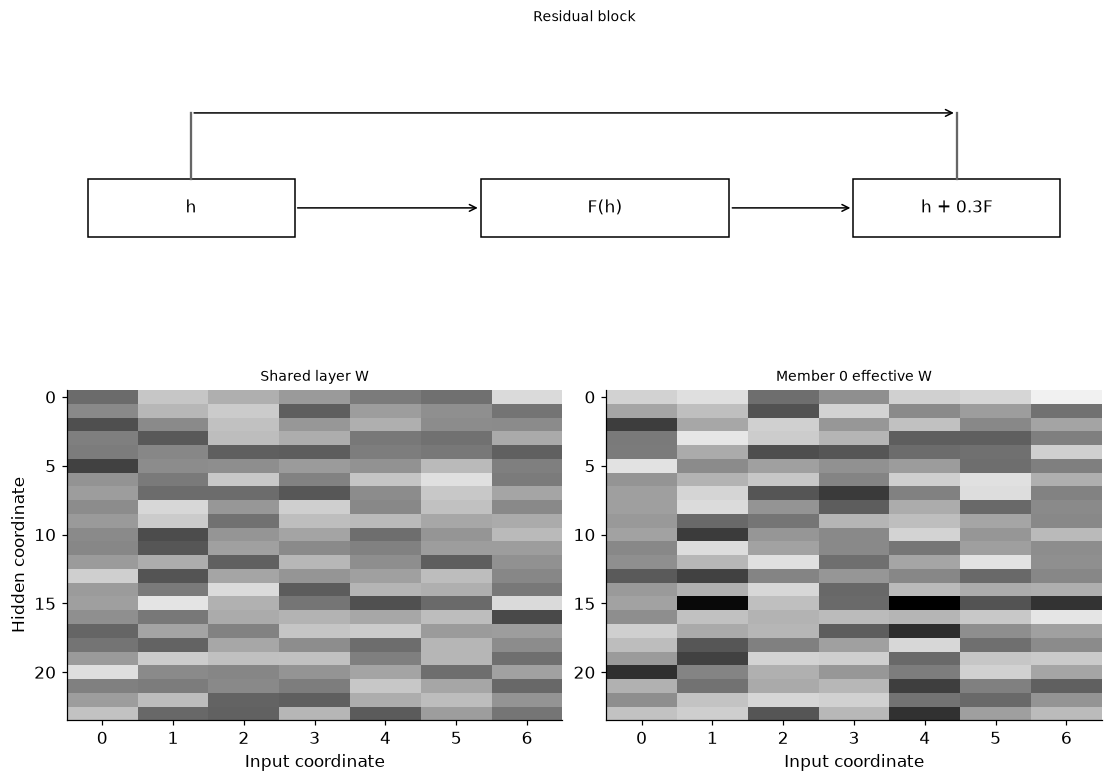

In [2]:
import copy
from sklearn.preprocessing import StandardScaler
from matplotlib.patches import Rectangle
building=np.repeat(np.arange(60),6);raw=.4*rng.normal(size=(60,4))[building]+rng.normal(size=(360,4));category=rng.integers(0,3,360)
target=1.5*np.sin(raw[:,0])+.4*raw[:,1]**2+.5*raw[:,2]*raw[:,3]+np.array([0.,.4,-.3])[category]+.2*rng.normal(size=60)[building]+rng.normal(0,.1,360)
train=building<40;dev=(building>=40)&(building<50);final=building>=50;scale=StandardScaler().fit(raw[train]);features=np.column_stack([scale.transform(raw),np.eye(3)[category]]);x=torch.tensor(features);y=torch.tensor(target)
assert set(building[train]).isdisjoint(building[final]) and x.shape==(360,7)
class MLP(nn.Module):
    def __init__(self):super().__init__();self.layers=nn.Sequential(nn.Linear(7,24),nn.ReLU(),nn.Linear(24,24),nn.ReLU(),nn.Linear(24,1))
    def forward(self,z):return self.layers(z)
class ResidualMLP(nn.Module):
    def __init__(self):
        super().__init__();self.input=nn.Linear(7,24);self.blocks=nn.ModuleList([nn.Sequential(nn.Linear(24,24),nn.ReLU(),nn.Linear(24,24)) for _ in range(2)]);self.output=nn.Linear(24,1)
    def forward(self,z):
        h=torch.relu(self.input(z))
        for block in self.blocks:h=h+.3*block(h)
        return self.output(h)
class FastLinear(nn.Module):
    def __init__(self,incoming,outgoing,members=4):
        super().__init__();self.weight=nn.Parameter(torch.empty(outgoing,incoming));nn.init.kaiming_uniform_(self.weight,a=np.sqrt(5));self.r=nn.Parameter(torch.where(torch.rand(members,incoming)<.5,-1.,1.));self.s=nn.Parameter(torch.where(torch.rand(members,outgoing)<.5,-1.,1.));self.bias=nn.Parameter(torch.zeros(members,outgoing))
    def forward(self,z):return torch.einsum('bki,oi->bko',z*self.r,self.weight)*self.s+self.bias
class FastEnsemble(nn.Module):
    def __init__(self):super().__init__();self.layers=nn.ModuleList([FastLinear(7,24),FastLinear(24,24),FastLinear(24,1)])
    def forward(self,z):
        h=z[:,None,:].expand(-1,4,-1)
        for index,layer in enumerate(self.layers):
            h=layer(h)
            if index<2:h=torch.relu(h)
        return h.squeeze(-1)
constructors={'MLP':MLP,'Residual':ResidualMLP,'Fast ensemble':FastEnsemble};rows=[];trained={};candidate_results=[]
for name,constructor in constructors.items():
    for replicate in range(3):
        candidates=[]
        for rate in [.005,.01]:
            torch.manual_seed(SEED+replicate);model=constructor();optimizer=torch.optim.AdamW(model.parameters(),lr=rate,weight_decay=.001);best=float('inf');best_state=None
            for step in range(200):
                model.train();optimizer.zero_grad();prediction=model(x[train]);loss=torch.mean((prediction-y[train,None])**2);loss.backward();optimizer.step()
                if (step+1)%5==0:
                    model.eval()
                    with torch.no_grad():validation=float(torch.mean((model(x[dev]).mean(1)-y[dev])**2))
                    if validation<best:best=validation;best_state=copy.deepcopy(model.state_dict());best_step=step+1
            model.load_state_dict(best_state);model.eval();candidates.append((best,rate,best_step,model));candidate_results.append({'architecture':name,'replicate':replicate,'learning_rate':rate,'development_MSE':best,'best_step':best_step})
        best,rate,best_step,model=min(candidates,key=lambda v:v[0])
        with torch.no_grad():member_predictions=model(x[final]).numpy();prediction=member_predictions.mean(1)
        row={'architecture':name,'replicate':replicate,'selected_rate':rate,'best_step':best_step,'development_MSE':best,'final_MSE':float(np.mean((prediction-target[final])**2)),'stored_parameters':sum(p.numel() for p in model.parameters()),'predictions_per_record':member_predictions.shape[1]};rows.append(row);trained[(name,replicate)]=model
        if name=='Fast ensemble':row['individual_member_MSE']=[float(np.mean((member_predictions[:,j]-target[final])**2)) for j in range(4)];row['mean_query_member_SD']=float(member_predictions.std(1).mean())
ensemble=trained[('Fast ensemble',0)];layer=ensemble.layers[0];probe=x[final][:5];expanded=probe[:,None,:].expand(-1,4,-1)
with torch.no_grad():
    effective=layer.weight[None,:,:]*layer.s[:,:,None]*layer.r[:,None,:];explicit=torch.stack([probe@effective[j].T+layer.bias[j] for j in range(4)],dim=1);torch.testing.assert_close(layer(expanded),explicit,atol=1e-12,rtol=1e-12)
# A separate training-fitted piecewise-linear numerical basis; no model below is silently refitted with it.
knots=np.quantile(raw[train,0],np.linspace(0,1,6));assert np.all(np.diff(knots)>0)
def numerical_basis(values):
    clipped=np.clip(values,knots[0],knots[-1]);index=np.clip(np.searchsorted(knots,clipped,side='right')-1,0,4);weight=(clipped-knots[index])/(knots[index+1]-knots[index]);basis=np.zeros((len(values),6));basis[np.arange(len(values)),index]=1-weight;basis[np.arange(len(values)),index+1]=weight;return basis
basis=numerical_basis(raw[final,0]);np.testing.assert_allclose(basis.sum(1),1);np.testing.assert_allclose(basis@knots,np.clip(raw[final,0],knots[0],knots[-1]),atol=1e-12)
RESULTS.update(comparisons=rows,candidates=candidate_results,split_buildings=[40,10,10],fast_weight_identity_checked=True,numerical_basis_shape=list(basis.shape),numerical_basis_clipped_final_count=int(np.sum((raw[final,0]<knots[0])|(raw[final,0]>knots[-1]))),shared_features=7,update_budget_per_candidate=200)
display(pd.DataFrame([{k:v for k,v in row.items() if k not in ['individual_member_MSE']} for row in rows]))
fig=plt.figure(figsize=(10,7),layout='constrained');grid=fig.add_gridspec(2,2);axes=[fig.add_subplot(grid[0,:]),fig.add_subplot(grid[1,0]),fig.add_subplot(grid[1,1])];ax=axes[0];ax.set(xlim=(0,5),ylim=(0,4));ax.axis('off')
for a,b,w,h,label in [(.1,1.5,1.,.7,'h'),(2.,1.5,1.2,.7,'F(h)'),(3.8,1.5,1.,.7,'h + 0.3F')]:ax.add_patch(Rectangle((a,b),w,h,fill=False));ax.text(a+w/2,b+h/2,label,ha='center',va='center')
for start,end in [((1.1,1.85),(2.,1.85)),((3.2,1.85),(3.8,1.85)),((.6,3.),(4.3,3.))]:ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'->'})
ax.plot([.6,.6],[2.2,3.],color='.4');ax.plot([4.3,4.3],[3.,2.2],color='.4');ax.set_title('Residual block')
shade=float(torch.max(torch.abs(torch.stack([layer.weight,effective[0]]))).detach());axes[1].imshow(layer.weight.detach().numpy(),aspect='auto',cmap='Greys',vmin=-shade,vmax=shade);axes[1].set(title='Shared layer W',xlabel='Input coordinate',ylabel='Hidden coordinate')
axes[2].imshow(effective[0].numpy(),aspect='auto',cmap='Greys',vmin=-shade,vmax=shade);axes[2].set(title='Member 0 effective W',xlabel='Input coordinate');plt.show()


<a id="comparison-limits"></a>
 ## Weight sharing is not free inference
 All four ensemble member predictions are computed and averaged. Sharing stored matrices reduces parameter storage relative to four independent copies, but does not make four predictions cost one forward pass. Member spread is not a calibrated predictive interval. The numerical basis uses training quantiles and clips new inputs outside its fitted range; its partition-of-unity and reconstruction identities are checked separately. It is not silently substituted into one candidate's features. More elaborate named architectures require their own exact implementations, tuning and entity-aware assessment before comparative claims.


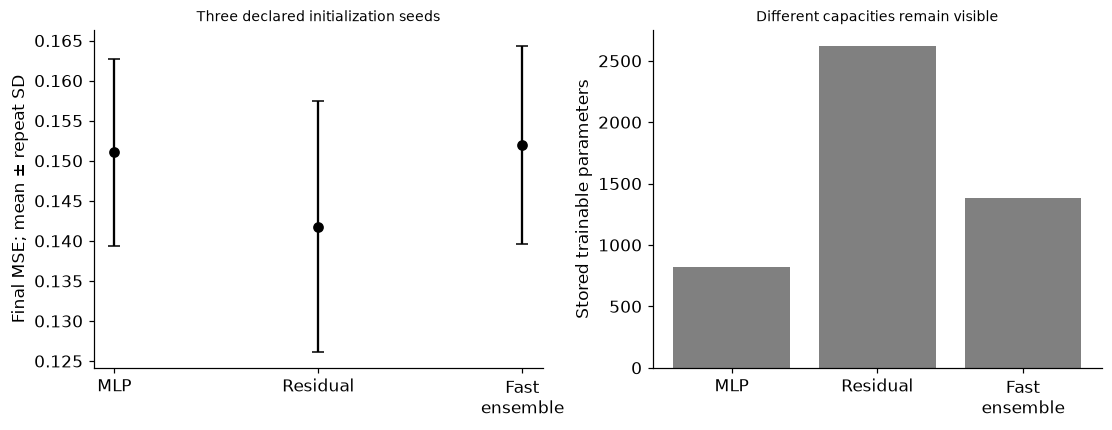

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,3.8));names=list(constructors)
for index,name in enumerate(names):
    subset=[r for r in rows if r['architecture']==name];values=np.array([r['final_MSE'] for r in subset]);axes[0].errorbar(index,values.mean(),yerr=values.std(ddof=1),fmt='o',color='black',capsize=4)
axes[0].set(xticks=range(3),xticklabels=['MLP','Residual','Fast\nensemble'],ylabel='Final MSE; mean ± repeat SD',title='Three declared initialization seeds')
axes[1].bar(range(3),[next(r['stored_parameters'] for r in rows if r['architecture']==name) for name in names],color='.5');axes[1].set(xticks=range(3),xticklabels=['MLP','Residual','Fast\nensemble'],ylabel='Stored trainable parameters',title='Different capacities remain visible');plt.show()
assert all(np.isfinite(r['final_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_108','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['whole-building tabular comparison', 'residual computation', 'actual rank-one fast-weight ensemble', 'numerical basis contract', 'named-model implementation boundaries'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["whole-building tabular comparison", "residual computation", "actual rank-one fast-weight ensemble", "numerical basis contract", "named-model implementation boundaries"], "elapsed_seconds": 2.557, "example_id": "code_108", "hardware": "Darwin arm64 CPU", "results": {"candidates": [{"architecture": "MLP", "best_step": 200, "development_MSE": 0.22431811987925557, "learning_rate": 0.005, "replicate": 0}, {"architecture": "MLP", "best_step": 125, "development_MSE": 0.25085964628617163, "learning_rate": 0.01, "replicate": 0}, {"architecture": "MLP", "best_step": 200, "development_MSE": 0.18472150755483785, "learning_rate": 0.005, "replicate": 1}, {"architecture": "MLP", "best_step": 195, "development_MSE": 0.2122262060278942, "learning_rate": 0.01, "replicate": 1}, {"architecture": "MLP", "best_step": 200, "development_MSE": 0.3151370591577223, "learning_rate": 0.005, "replicate": 2}, {"architecture": "MLP", "best_step": 200, "development_MS